In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

In [2]:
PROJECT_DIR = Path(
    "/Users/kakulrajput/Documents/Image_Detection"
)

DATASET_DIR = (
    PROJECT_DIR / "data" / "processed" / "image_dataset"
)

MODEL_PATH = (
    PROJECT_DIR / "models" / "image_mobilenetv3_baseline.pt"
)

REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print("Device:", DEVICE)
print("Dataset exists:", DATASET_DIR.exists())
print("Checkpoint exists:", MODEL_PATH.exists())

Device: mps
Dataset exists: True
Checkpoint exists: True


In [3]:
checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True,
)

print("Architecture:", checkpoint["architecture"])
print("Class mapping:", checkpoint["class_to_idx"])
print("Image size:", checkpoint["image_size"])
print("Best validation F1:", checkpoint["best_val_f1"])

Architecture: mobilenet_v3_large
Class mapping: {'safe': 0, 'unsafe': 1}
Image size: 224
Best validation F1: 0.8430379746835444


In [4]:
IMAGE_SIZE = checkpoint["image_size"]
MEAN = checkpoint["mean"]
STD = checkpoint["std"]

model = models.mobilenet_v3_large(weights=None)

num_features = model.classifier[-1].in_features

model.classifier[-1] = nn.Linear(
    num_features,
    2,
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True,
)

model = model.to(DEVICE)
model.eval()

print("Model loaded successfully.")

Model loaded successfully.


In [5]:
def rgb_loader(path):
    from PIL import Image

    with Image.open(path) as image:
        return image.convert("RGB")


eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=MEAN,
        std=STD,
    ),
])

val_dataset = datasets.ImageFolder(
    DATASET_DIR / "val",
    transform=eval_transform,
    loader=rgb_loader,
)

print("Classes:", val_dataset.class_to_idx)
print("Validation images:", len(val_dataset))

assert val_dataset.class_to_idx == checkpoint["class_to_idx"]

Classes: {'safe': 0, 'unsafe': 1}
Validation images: 771


In [6]:
BATCH_SIZE = 16

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

print("Validation batches:", len(val_loader))

Validation batches: 49


In [7]:
all_labels = []
all_predictions = []
all_unsafe_probabilities = []

model.eval()

with torch.inference_mode():
    for images, labels in val_loader:
        images = images.to(DEVICE)

        logits = model(images)

        probabilities = torch.softmax(logits, dim=1)

        predictions = probabilities.argmax(dim=1)

        all_labels.extend(labels.tolist())

        all_predictions.extend(
            predictions.cpu().tolist()
        )

        all_unsafe_probabilities.extend(
            probabilities[:, 1].cpu().tolist()
        )

print("Predictions generated:", len(all_predictions))

/Users/kakulrajput/Documents/Image_Detection/venv/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Predictions generated: 771


In [8]:
accuracy = accuracy_score(
    all_labels,
    all_predictions,
)

precision = precision_score(
    all_labels,
    all_predictions,
    zero_division=0,
)

recall = recall_score(
    all_labels,
    all_predictions,
    zero_division=0,
)

f1 = f1_score(
    all_labels,
    all_predictions,
    zero_division=0,
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Accuracy:  0.8392
Precision: 0.8582
Recall:    0.8284
F1-score:  0.8430


In [9]:
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=[0, 1],
        target_names=["safe", "unsafe"],
        zero_division=0,
        digits=4,
    )
)

              precision    recall  f1-score   support

        safe     0.8198    0.8509    0.8351       369
      unsafe     0.8582    0.8284    0.8430       402

    accuracy                         0.8392       771
   macro avg     0.8390    0.8397    0.8391       771
weighted avg     0.8399    0.8392    0.8392       771



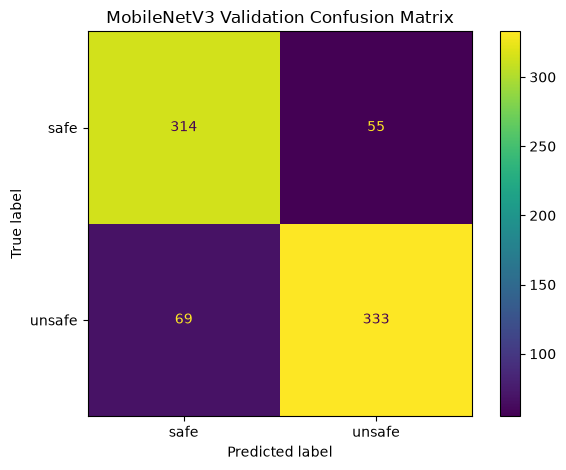

[[314  55]
 [ 69 333]]


In [10]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1],
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["safe", "unsafe"],
)

disp.plot(values_format="d")

plt.title("MobileNetV3 Validation Confusion Matrix")
plt.tight_layout()
plt.show()

print(cm)

In [11]:
predictions_df = pd.DataFrame({
    "path": [path for path, _ in val_dataset.samples],
    "true_label": all_labels,
    "predicted_label": all_predictions,
    "unsafe_probability": all_unsafe_probabilities,
})

predictions_df["true_class"] = predictions_df["true_label"].map({
    0: "safe",
    1: "unsafe",
})

predictions_df["predicted_class"] = predictions_df["predicted_label"].map({
    0: "safe",
    1: "unsafe",
})

predictions_df["correct"] = (
    predictions_df["true_label"]
    == predictions_df["predicted_label"]
)

predictions_path = REPORT_DIR / "validation_predictions.csv"

predictions_df.to_csv(
    predictions_path,
    index=False,
)

print("Saved:", predictions_path)
print(predictions_df.head())

Saved: /Users/kakulrajput/Documents/Image_Detection/reports/validation_predictions.csv
                                                path  true_label  \
0  /Users/kakulrajput/Documents/Image_Detection/d...           0   
1  /Users/kakulrajput/Documents/Image_Detection/d...           0   
2  /Users/kakulrajput/Documents/Image_Detection/d...           0   
3  /Users/kakulrajput/Documents/Image_Detection/d...           0   
4  /Users/kakulrajput/Documents/Image_Detection/d...           0   

   predicted_label  unsafe_probability true_class predicted_class  correct  
0                0            0.041331       safe            safe     True  
1                0            0.046776       safe            safe     True  
2                0            0.125400       safe            safe     True  
3                0            0.279730       safe            safe     True  
4                0            0.138735       safe            safe     True  
